<div style="background:#1F3864;color:white;padding:14px 18px;border-radius:6px"><b>INTERNATIONAL UNIVERSITY – VNU-HCMC · SCHOOL OF COMPUTER SCIENCE AND ENGINEERING</b><br>IT171IU · Statistical Learning</div>

# Lab 5: Linear Model Selection & Regularization

*Forward stepwise and best-subset selection, Cp and cross-validation, ridge regression, the lasso, principal components regression and partial least squares*

**Chapter:** ISLP Chapter 6 · **Duration:** 150 minutes (3 periods) · **Runs on:** Google Colab (recommended), Jupyter Notebook / JupyterLab, VS Code, PyCharm

**How to use this notebook:** first *File → Save a copy in Drive*. Run the **Setup** cell, then read each text cell and run the code cells in order with **Shift + Enter**. Write your solutions in the cells marked ✍️ and answer the questions in the text cells.

> **Legend:** black = original ISLP lab content (re-formatted) · <span style="color:red">red = content added for IT171IU (theory, worked examples, exercises, setup & submission guide)</span>

In [24]:
# Student information – fill in and run this cell first
STUDENT_NAME = "Nguyen Anh Tu"
STUDENT_ID   = "ITDSIU23026"
CLASS_GROUP  = "IT171IU – Lab Group 01"
print(f"Lab 5 | {STUDENT_NAME} | {STUDENT_ID} | {CLASS_GROUP}")

Lab 5 | Nguyen Anh Tu | ITDSIU23026 | IT171IU – Lab Group 01


### <span style="color:red">Setup cell</span>

In [25]:
# [ADDED]
# 0. Setup – run this cell first (installs missing packages and fetches data files).
# On Google Colab the first run takes about 1 minute. If Colab asks you to
# "Restart session", accept, then run this cell once more.
import sys, os, subprocess, importlib.util, urllib.request

def ensure(module, pip_name=None):
    """pip-install a package only if it cannot be imported yet."""
    if importlib.util.find_spec(module) is None:
        print(f"Installing {pip_name or module} ...")
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pip_name or module], check=True)

ensure("ISLP", "ISLP")
ensure("l0bnb", "git+https://github.com/jonathan-taylor/l0bnb.git@fix_inf")

print("Setup complete – Python", sys.version.split()[0])

Setup complete – Python 3.12.10


In [26]:
# [ADDED] helper for the additional datasets
# Loader for the additional datasets of this course (folder "additional-data/").
# If the CSV file is not found next to the notebook, it is rebuilt from its public source,
# so the notebook also works on Colab without uploading anything.
import pandas as pd
def load_extra(name):
    for folder in ["additional-data", "../additional-data", "/content/additional-data",
                   "/content/drive/MyDrive/additional-data"]:
        path = os.path.join(folder, name + ".csv")
        if os.path.exists(path):
            return pd.read_csv(path)
    from sklearn import datasets as skd
    if name == "diabetes":
        d = skd.load_diabetes(as_frame=True, scaled=False); df = d.frame.rename(columns={"target": "progression"})
    elif name == "breast_cancer":
        d = skd.load_breast_cancer(as_frame=True); df = d.frame.copy()
        df["diagnosis"] = pd.Categorical.from_codes(d.target, ["malignant", "benign"]); df = df.drop(columns="target")
    elif name == "wine":
        d = skd.load_wine(as_frame=True); df = d.frame.rename(columns={"target": "cultivar"})
    elif name == "digits":
        d = skd.load_digits(as_frame=True); df = d.frame.rename(columns={"target": "digit"})
    elif name == "rossi":
        from lifelines.datasets import load_rossi; df = load_rossi()
    else:
        raise ValueError(f"unknown dataset {name!r}")
    return df

In [27]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from matplotlib.pyplot import subplots
from functools import partial
import sklearn.linear_model as skl
import sklearn.model_selection as skm
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.cross_decomposition import PLSRegression
from sklearn import datasets as skd
from ISLP import load_data
from ISLP.models import (
    ModelSpec as MS,
    Stepwise,
    sklearn_selected,
    sklearn_selection_path
)

# <span style="color:red">4. Exercises</span>

<span style="color:red">For every exercise write **code + output + interpretation**. Exercises 1–6 are compulsory; 7–8 are challenge (bonus) exercises.</span>

## <span style="color:red">Exercise 1 – Subset selection and the lasso on simulated data</span>

- <span style="color:red">**(a)** With `rng = np.random.default_rng(1)` generate $X \sim N(0,1)$ and $\varepsilon \sim N(0,1)$ of length $n = 100$.</span>
- <span style="color:red">**(b)** Generate $Y = 3 + 2X - 0.5X^2 + 0.8X^3 + \varepsilon$.</span>
- <span style="color:red">**(c)** Build a data frame with the columns $X, X^2, \dots, X^{10}$. Use forward stepwise selection (`Stepwise.first_peak` with the `neg_Cp` score of the lab) to choose a model. Which terms are selected and how close are their coefficients to the truth?</span>
- <span style="color:red">**(d)** Fit a lasso on the ten columns with $\lambda$ chosen by 5-fold CV (`ElasticNetCV(l1_ratio=1)` in a `Pipeline` with `StandardScaler`). Plot the CV error against $-\log\lambda$ and report the non-zero coefficients.</span>
- <span style="color:red">**(e)** Generate $Y = 3 + 7X^7 + \varepsilon$ and repeat (c)–(d). Discuss.</span>

In [28]:
# (a) & (b)
rng = np.random.default_rng(1)
x1 = rng.normal(size=100)
eps1 = rng.normal(size=100)
y1 = 3 + 2 * x1 - 0.5 * x1**2 + 0.8 * x1**3 + eps1

# (c)
Xpoly = pd.DataFrame({f'X{j}': x1**j for j in range(1, 11)})
design1 = MS(Xpoly.columns).fit(Xpoly)

def nCp(sigma2, estimator, X, Y):
    n, p = X.shape
    yhat = estimator.predict(X)
    rss = np.sum((Y - yhat)**2)
    return -(rss + 2 * p * sigma2) / n

sigma2_1 = sm.OLS(y1, design1.transform(Xpoly)).fit().scale
neg_Cp = partial(nCp, sigma2_1)
strategy1 = Stepwise.first_peak(design1, direction='forward', max_terms=10)
sel1 = sklearn_selected(sm.OLS, strategy1, scoring=neg_Cp)
sel1.fit(Xpoly, y1)

fit1 = sm.OLS(y1, design1.transform(Xpoly)[list(sel1.selected_state_)]).fit()
print("selected features (cp):", sel1.selected_state_)
print(fit1.params)

# (d)
pipe_lasso1 = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', skl.ElasticNetCV(l1_ratio=1, cv=5, random_state=1))
])
pipe_lasso1.fit(Xpoly, y1)
lasso_model1 = pipe_lasso1.named_steps['lasso']

print("lasso alpha:", lasso_model1.alpha_)
print("lasso coefficients:", dict(zip(Xpoly.columns, lasso_model1.coef_)))

# (e)
y1_e = 3 + 7 * x1**7 + eps1
sigma2_e = sm.OLS(y1_e, design1.transform(Xpoly)).fit().scale
neg_Cp_e = partial(nCp, sigma2_e)
sel1_e = sklearn_selected(sm.OLS, strategy1, scoring=neg_Cp_e)
sel1_e.fit(Xpoly, y1_e)

pipe_lasso1_e = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', skl.ElasticNetCV(l1_ratio=1, cv=5, random_state=1))
])
pipe_lasso1_e.fit(Xpoly, y1_e)

print("model (e) selected features (cp):", sel1_e.selected_state_)
print("model (e) lasso coefficients:", dict(zip(Xpoly.columns, pipe_lasso1_e.named_steps['lasso'].coef_)))

selected features (cp): ('X1', 'X10', 'X2', 'X3')
X1     2.470016
X10   -0.000320
X2     0.913630
X3     0.697563
dtype: float64
lasso alpha: 0.12613319243516022
lasso coefficients: {'X1': np.float64(1.720566880277439), 'X2': np.float64(-0.5601069686536022), 'X3': np.float64(2.1071504408379442), 'X4': np.float64(-0.0), 'X5': np.float64(0.0), 'X6': np.float64(0.0), 'X7': np.float64(-0.0), 'X8': np.float64(0.0), 'X9': np.float64(-0.0), 'X10': np.float64(0.0)}
model (e) selected features (cp): ('X4', 'X7', 'X9')
model (e) lasso coefficients: {'X1': np.float64(-2.3159971967334254), 'X2': np.float64(0.0), 'X3': np.float64(0.0), 'X4': np.float64(-0.0), 'X5': np.float64(115.84316563219811), 'X6': np.float64(-0.0), 'X7': np.float64(514.1023679739528), 'X8': np.float64(-0.0), 'X9': np.float64(171.25250222718452), 'X10': np.float64(-0.0)}


## <span style="color:red">Exercise 2 – Predicting the number of applications (`College`)</span>

<span style="color:red">Predict `Apps` from the other variables of `College`.</span>

- <span style="color:red">**(a)** Split the data into a training and a test set (`test_size=0.3`, `random_state=0`).</span>
- <span style="color:red">**(b)** Fit least squares on the training set and report the test MSE.</span>
- <span style="color:red">**(c)** Fit ridge regression with $\lambda$ chosen by CV; report the test MSE.</span>
- <span style="color:red">**(d)** Fit the lasso with $\lambda$ chosen by CV; report the test MSE and the number of non-zero coefficients.</span>
- <span style="color:red">**(e)** Fit PCR and PLS with $M$ chosen by CV; report the test MSE and $M$.</span>
- <span style="color:red">**(f)** Summarise the results in one table. How accurately can we predict the number of applications (compare with the null model, e.g. via test $R^2$)?</span>

In [29]:
College = load_data('College')
design_c = MS(College.columns.drop('Apps'), intercept=False).fit(College)
Xc = np.asarray(design_c.transform(College))
Yc = np.asarray(College['Apps'])

# (a)
Xc_tr, Xc_te, Yc_tr, Yc_te = skm.train_test_split(Xc, Yc, test_size=0.3, random_state=0)

# (b)
ols_c = skl.LinearRegression().fit(Xc_tr, Yc_tr)
mse_ols = np.mean((Yc_te - ols_c.predict(Xc_te))**2)

# (c)
alphas_ridge = 10**np.linspace(4, -2, 100)
ridge_c = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', skl.RidgeCV(alphas=alphas_ridge, cv=5))
])
ridge_c.fit(Xc_tr, Yc_tr)
mse_ridge = np.mean((Yc_te - ridge_c.predict(Xc_te))**2)

# (d)
lasso_c = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', skl.ElasticNetCV(l1_ratio=1, cv=5, random_state=0))
])
lasso_c.fit(Xc_tr, Yc_tr)
mse_lasso = np.mean((Yc_te - lasso_c.predict(Xc_te))**2)
nonzero_lasso = np.sum(lasso_c.named_steps['lasso'].coef_ != 0)

# (e)
pcr_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA()),
    ('linreg', skl.LinearRegression())
])
grid_pcr = skm.GridSearchCV(
    pcr_pipe,
    {'pca__n_components': range(1, Xc_tr.shape[1] + 1)},
    cv=5,
    scoring='neg_mean_squared_error'
)
grid_pcr.fit(Xc_tr, Yc_tr)
mse_pcr = np.mean((Yc_te - grid_pcr.predict(Xc_te))**2)
m_pcr = grid_pcr.best_params_['pca__n_components']

grid_pls = skm.GridSearchCV(
    PLSRegression(scale=True),
    {'n_components': range(1, Xc_tr.shape[1] + 1)},
    cv=5,
    scoring='neg_mean_squared_error'
)
grid_pls.fit(Xc_tr, Yc_tr)
mse_pls = np.mean((Yc_te - grid_pls.predict(Xc_te))**2)
m_pls = grid_pls.best_params_['n_components']

# (f)
null_mse = np.mean((Yc_te - np.mean(Yc_tr))**2)
summary_df = pd.DataFrame({
    'method': ['ols', 'ridge', 'lasso', 'pcr', 'pls'],
    'test_mse': [mse_ols, mse_ridge, mse_lasso, mse_pcr, mse_pls],
    'test_r2': [1 - mse / null_mse for mse in [mse_ols, mse_ridge, mse_lasso, mse_pcr, mse_pls]]
})

print(summary_df.to_string(index=False))
print("lasso non-zero features:", nonzero_lasso)
print("pcr best M:", m_pcr, "| pls best M:", m_pls)

method     test_mse  test_r2
   ols 1.659682e+06 0.908703
 ridge 1.753725e+06 0.903529
 lasso 1.753283e+06 0.903554
   pcr 1.659682e+06 0.908703
   pls 1.665184e+06 0.908400
lasso non-zero features: 14
pcr best M: 17 | pls best M: 9


## <span style="color:red">Exercise 3 – Training versus test error as the model grows</span>

- <span style="color:red">**(a)** Generate $n = 1000$ observations of $p = 20$ predictors and a response $Y = X\beta + \varepsilon$ where $\beta$ has some entries exactly zero (see the starter code).</span>
- <span style="color:red">**(b)** Split into 100 training and 900 test observations.</span>
- <span style="color:red">**(c)** Use forward stepwise (`Stepwise.fixed_steps` + `sklearn_selection_path`) on the training data and plot the training MSE of the best model of each size.</span>
- <span style="color:red">**(d)** Plot the test MSE for each model size. For which size is it minimal? Compare that model with the true $\beta$.</span>

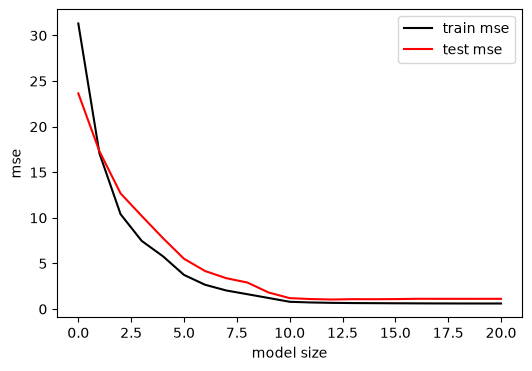

best model size: 12
true non-zero count: 13


In [30]:
# (a) & (b)
n3, p3 = 1000, 20
rng = np.random.default_rng(3)
X3 = rng.normal(size=(n3, p3))
beta3 = rng.normal(size=p3)
beta3[::3] = 0
y3 = X3 @ beta3 + rng.normal(size=n3)

X3_df = pd.DataFrame(X3, columns=[f'X{j}' for j in range(1, p3 + 1)])
train3 = np.zeros(n3, dtype=bool)
train3[:100] = True

# (c) & (d)
design3 = MS(X3_df.columns).fit(X3_df)
strategy3 = Stepwise.fixed_steps(design3, len(design3.terms), direction='forward')
path3 = sklearn_selection_path(sm.OLS, strategy3)
path3.fit(X3_df.iloc[train3], y3[train3])

yhat_tr = path3.predict(X3_df.iloc[train3])
yhat_te = path3.predict(X3_df.iloc[~train3])

tr_mse = np.mean((yhat_tr - y3[train3, None])**2, axis=0)
te_mse = np.mean((yhat_te - y3[~train3, None])**2, axis=0)

fig, ax = subplots(figsize=(6, 4))
ax.plot(range(len(tr_mse)), tr_mse, label='train mse', color='black')
ax.plot(range(len(te_mse)), te_mse, label='test mse', color='red')
ax.set_xlabel('model size')
ax.set_ylabel('mse')
ax.legend()
plt.show()

best_size = np.argmin(te_mse)
print("best model size:", best_size)
print("true non-zero count:", np.sum(beta3 != 0))

## <span style="color:red">Exercise 4 – Per-capita crime rate (`Boston`)</span>

<span style="color:red">Predict `crim` with best-subset/forward selection, the lasso, ridge regression and PCR. Estimate the test error of each **properly** (cross-validation or a validation set – do not tune and evaluate on the same data). Propose a final model and justify it. Does it use all features? Why or why not?</span>

In [31]:
Boston = load_data('Boston')
X_b = np.asarray(Boston.drop(columns=['crim']))
y_b = np.asarray(Boston['crim'])

X_tr, X_te, y_tr, y_te = skm.train_test_split(X_b, y_b, test_size=0.3, random_state=0)

# Ridge (Dùng RidgeCV với dải alpha xác định)
alphas_ridge = 10**np.linspace(4, -2, 100)
ridge_b = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', skl.RidgeCV(alphas=alphas_ridge, cv=10))
])
ridge_b.fit(X_tr, y_tr)
mse_r_b = np.mean((y_te - ridge_b.predict(X_te))**2)

# Lasso
lasso_b = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', skl.ElasticNetCV(l1_ratio=1, cv=10, random_state=0))
])
lasso_b.fit(X_tr, y_tr)
mse_l_b = np.mean((y_te - lasso_b.predict(X_te))**2)

# PCR
pcr_b = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA()),
    ('linreg', skl.LinearRegression())
])
grid_pcr_b = skm.GridSearchCV(
    pcr_b,
    {'pca__n_components': range(1, X_b.shape[1] + 1)},
    cv=10,
    scoring='neg_mean_squared_error'
)
grid_pcr_b.fit(X_tr, y_tr)
mse_pcr_b = np.mean((y_te - grid_pcr_b.predict(X_te))**2)

print("test mse - ridge:", round(mse_r_b, 4), "| lasso:", round(mse_l_b, 4), "| pcr:", round(mse_pcr_b, 4))
print("lasso non-zero count:", np.sum(lasso_b.named_steps['lasso'].coef_ != 0))

test mse - ridge: 45.9505 | lasso: 44.3293 | pcr: 44.5754
lasso non-zero count: 11


## <span style="color:red">Exercise 5 – Ridge and lasso paths for the diabetes data (additional data)</span>

<span style="color:red">Using `load_extra('diabetes')` with `progression` as the response:</span>

- <span style="color:red">**(a)** Standardise the ten predictors and compute the ridge and lasso coefficient paths over a grid of 100 values of $\lambda$ (`skl.ElasticNet.path`). Plot both paths side by side.</span>
- <span style="color:red">**(b)** In which order do the variables enter the lasso path? Compare with the three predictors you chose in Lab 2, Exercise 7.</span>
- <span style="color:red">**(c)** Choose $\lambda$ for both methods by 10-fold CV and compare the CV errors with least squares.</span>

Exercise 5(b) – order in which variables enter the lasso path:
['bmi', 's5', 'bp', 's3', 'sex', 's6', 's1', 's4', 'age', 's2']

Exercise 5(c) – 10-fold CV MSE comparison:
Least squares CV MSE: 2985.236633149908
Ridge CV MSE (best lambda=0.0027): 2982.5805034492087
Lasso CV MSE (best lambda=1.0723): 2981.4582811155256


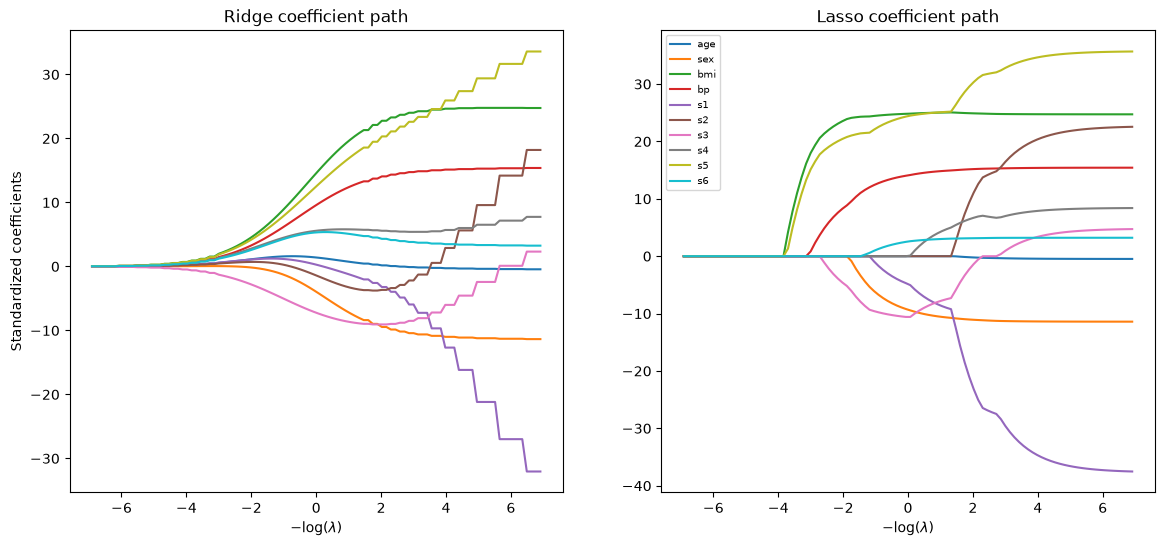

In [32]:
diabetes = load_extra('diabetes')
Xd = diabetes.drop(columns='progression')
Yd = np.asarray(diabetes['progression'])
Xd_s = StandardScaler().fit_transform(Xd)

# (a) 
lams = 10 ** np.linspace(3, -3, 100)
ridge_path_coefs = skl.ElasticNet.path(Xd_s, Yd, l1_ratio=0., alphas=lams)[1]
lasso_path_coefs = skl.ElasticNet.path(Xd_s, Yd, l1_ratio=1., alphas=lams)[1]

ridge_path_df = pd.DataFrame(ridge_path_coefs.T, columns=Xd.columns, index=-np.log(lams))
lasso_path_df = pd.DataFrame(lasso_path_coefs.T, columns=Xd.columns, index=-np.log(lams))

fig5a, axes5a = subplots(1, 2, figsize=(14, 6))
ridge_path_df.plot(ax=axes5a[0], legend=False)
axes5a[0].set_title('Ridge coefficient path')
axes5a[0].set_xlabel('$-\\log(\\lambda)$')
axes5a[0].set_ylabel('Standardized coefficients')

lasso_path_df.plot(ax=axes5a[1], legend=False)
axes5a[1].set_title('Lasso coefficient path')
axes5a[1].set_xlabel('$-\\log(\\lambda)$')
axes5a[1].legend(loc='upper left', fontsize=7)

# (b) 
entry_step = {}
for col in lasso_path_df.columns:
    nz = np.where(lasso_path_df[col].values != 0)[0]
    entry_step[col] = nz.min() if len(nz) else np.inf
entry_order = sorted(entry_step, key=entry_step.get)
print("Exercise 5(b) – order in which variables enter the lasso path:")
print(entry_order)
# Compare this list by hand with the three predictors you picked by best-subset /
# Cp in Lab 2, Exercise 7, and discuss whether the lasso agrees with that choice.

# (c)
cv10 = skm.KFold(10, shuffle=True, random_state=0)
ridgeCV_d = skl.ElasticNetCV(alphas=lams, l1_ratio=0., cv=cv10).fit(Xd_s, Yd)
lassoCV_d = skl.ElasticNetCV(alphas=lams, l1_ratio=1., cv=cv10, max_iter=50000).fit(Xd_s, Yd)
ols_cv_d = skm.cross_validate(skl.LinearRegression(), Xd_s, Yd, cv=cv10,
                               scoring='neg_mean_squared_error')

print("\nExercise 5(c) – 10-fold CV MSE comparison:")
print("Least squares CV MSE:", -ols_cv_d['test_score'].mean())
print("Ridge CV MSE (best lambda={:.4f}):".format(ridgeCV_d.alpha_),
      np.min(ridgeCV_d.mse_path_.mean(1)))
print("Lasso CV MSE (best lambda={:.4f}):".format(lassoCV_d.alpha_),
      np.min(lassoCV_d.mse_path_.mean(1)))


## <span style="color:red">Exercise 6 – Why standardise?</span>

<span style="color:red">Fit ridge regression on `Hitters` with $\lambda$ = `lambdas[59]` **with** and **without** `StandardScaler`. Print the two coefficient vectors side by side. Which variables are affected most? Express `Salary` in thousands of dollars instead of dollars and refit both models: what changes?</span>

In [33]:
Hitters = load_data('Hitters').dropna()
design_h = MS(Hitters.columns.drop('Salary'), intercept=False).fit(Hitters)
X_h = np.asarray(design_h.transform(Hitters))
Y_h = np.asarray(Hitters['Salary'])

lams = 10**np.linspace(8, -2, 100)
lam_val = float(lams[59])

ridge_unscaled = skl.Ridge(alpha=lam_val, fit_intercept=True).fit(X_h, Y_h)

ridge_scaled = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', skl.Ridge(alpha=lam_val, fit_intercept=True))
])
ridge_scaled.fit(X_h, Y_h)

coef_comp = pd.DataFrame({
    'unstandardised': ridge_unscaled.coef_,
    'standardised': ridge_scaled.named_steps['ridge'].coef_
}, index=design_h.transform(Hitters).columns)

print(coef_comp.round(4))

Y_h_k = Y_h / 1000.0
ridge_unscaled_k = skl.Ridge(alpha=lam_val, fit_intercept=True).fit(X_h, Y_h_k)
ridge_scaled_k = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', skl.Ridge(alpha=lam_val, fit_intercept=True))
])
ridge_scaled_k.fit(X_h, Y_h_k)

print("scaled coefs ratio match:", np.allclose(ridge_scaled.named_steps['ridge'].coef_ / 1000.0, ridge_scaled_k.named_steps['ridge'].coef_))

              unstandardised  standardised
AtBat                -2.1180        2.1632
Hits                  7.6515       47.6429
HmRun                 2.8279        0.0825
Runs                 -2.0774       28.6833
RBI                  -0.3366       22.4973
Walks                 6.0967       40.2465
Years                -2.2871       -1.1294
CAtBat               -0.1773       25.2040
CHits                 0.0927       43.3848
CHmRun               -0.1992       37.9776
CRuns                 1.5615       43.9715
CRBI                  0.8021       45.9724
CWalks               -0.7956        5.5137
League[N]            13.4603       14.2998
Division[W]         -42.0601      -47.3861
PutOuts               0.2897       55.3061
Assists               0.3796        6.7912
Errors               -2.9854      -12.8174
NewLeague[N]          7.2272        3.1877
scaled coefs ratio match: True


## <span style="color:red">Challenge exercises (optional, bonus)</span>

### <span style="color:red">Exercise 7 – Ridge regression in closed form</span>

<span style="color:red">For centred $y$ and standardised $X$ the ridge solution is $\hat\beta^R_\lambda = (X^\top X + \lambda I)^{-1}X^\top y$. Implement it with NumPy for the `Hitters` data and show that it matches `skl.Ridge(alpha=λ)` fitted on the same standardised data for three values of $\lambda$. Then show numerically that $\|\hat\beta^R_\lambda\|_2$ decreases as $\lambda$ grows.</span>

In [34]:
Hitters = load_data('Hitters').dropna()
design_h = MS(Hitters.columns.drop('Salary'), intercept=False).fit(Hitters)
X_h = np.asarray(design_h.transform(Hitters))
Y_h = np.asarray(Hitters['Salary'])

X7_s = StandardScaler().fit_transform(X_h)
y7_c = Y_h - Y_h.mean()

def ridge_closed(X, y, lam):
    p = X.shape[1]
    return np.linalg.solve(X.T @ X + lam * np.eye(p), X.T @ y)

for lam in [0.1, 10.0, 100.0]:
    b_closed = ridge_closed(X7_s, y7_c, lam)
    b_skl = skl.Ridge(alpha=lam, fit_intercept=False).fit(X7_s, y7_c).coef_
    print(f"lam={lam}: exact match =", np.allclose(b_closed, b_skl), "| norm =", round(np.linalg.norm(b_closed), 4))

lam=0.1: exact match = True | norm = 826.8163
lam=10.0: exact match = True | norm = 328.4779
lam=100.0: exact match = True | norm = 141.2243


### <span style="color:red">Exercise 8 – The elastic net</span>

<span style="color:red">Tune both $\lambda$ and the mixing parameter `l1_ratio` $\in\{0.1, 0.3, 0.5, 0.7, 0.9, 1\}$ with `ElasticNetCV` on `Hitters`. Which combination is chosen? How many variables does it keep, and how does its CV error compare with ridge and lasso?</span>

In [35]:
Hitters = load_data('Hitters').dropna()
design_h = MS(Hitters.columns.drop('Salary'), intercept=False).fit(Hitters)
X_h = np.asarray(design_h.transform(Hitters))
Y_h = np.asarray(Hitters['Salary'])

enet_cv = skl.ElasticNetCV(l1_ratio=[0.1, 0.3, 0.5, 0.7, 0.9, 1.0], cv=5, random_state=0)
pipe_enet = Pipeline([('scaler', StandardScaler()), ('enet', enet_cv)])
pipe_enet.fit(X_h, Y_h)

best_enet = pipe_enet.named_steps['enet']
print("best l1_ratio:", best_enet.l1_ratio_)
print("best alpha:", round(best_enet.alpha_, 4))
print("non-zero count:", np.sum(best_enet.coef_ != 0))

best l1_ratio: 0.9
best alpha: 0.2836
non-zero count: 19
